# Cross-cell-line validation

In [1]:
import sys
import os
import argparse
import numpy as np
import random
import torch

sys.path.append('../G2CP/backbone_model/GEARS')
from gears import PertData, GEARS
from gears.utils import print_sys

In [2]:
datasets = ['LINCS-A549', 'LINCS-A375', 'LINCS-MCF7', 'LINCS-PC3', 'LINCS-HT29']

In [3]:
TRAIN_MODE = 'pretrain-finetune-ts'
SEED = 0
TRAIN_FRAC = 0.0
VAL_FRAC = 0.1
BATCH_SIZE = 32
LR = 1e-3
EPOCHS = 20
WEIGHT_DECAY = 5e-4
NO_PERTURB = False

save_path = '../G2CP/saved_models/LINCS_ts'

exp_trail = 'new_' + TRAIN_MODE+'_'+str(SEED)+'_'+str(TRAIN_FRAC)

In [6]:
model_list = []
dataloader_list = []

for cell_line in datasets:
    print(f"======================={cell_line}=======================")
    # prepare data
    pert_data = PertData(data_path='../G2CP/data')
    pert_data.load(
        data_name=cell_line,
        pert_type_col_name = 'pert_type',
        perturbagen_col_name = 'condition',
        control_key = 'ctrl'
        )
    pert_data.prepare_split(
        split=TRAIN_MODE, 
        seed=SEED, 
        train_ptbg_set_frac = TRAIN_FRAC,       
        val_ptbg_set_frac = VAL_FRAC,
        )
    pert_data.get_dataloader(
        batch_size=BATCH_SIZE,
        test_batch_size=128,
        )
    dataloader_list.append(pert_data.dataloader)

    # prepare model
    model_path = os.path.join(save_path, str(cell_line), exp_trail)
    exp_name = model_path.split('/')[-1]
    gears_model = GEARS(
        pert_data, 
        device='cuda:0', 
        weight_bias_track=False, 
        proj_name=str(cell_line), 
        exp_name=exp_trail+'_'+exp_name,
        save_path=model_path,
        )
    # load model
    gears_model.load_pretrained(model_path, 'finetune_model')
    model_list.append(gears_model)
    


=======================LINCS-A549=======================


genetic ptbgs: 4991
chemical ptbgs: 6300
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
train ptbgs: 462
val ptbgs: 559
test ptbgs: 5279
pretrain_train ptbgs: 4492
pretrain_val ptbgs: 499
Done!
Creating dataloaders....
Done!


here1
=======================LINCS-A375=======================


genetic ptbgs: 4985
chemical ptbgs: 4019
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
train ptbgs: 462
val ptbgs: 559
test ptbgs: 2998
pretrain_train ptbgs: 4487
pretrain_val ptbgs: 498
Done!
Creating dataloaders....
Done!


here1
=======================LINCS-MCF7=======================


...

here1
=======================LINCS-PC3=======================


genetic ptbgs: 4980
chemical ptbgs: 7676
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
train ptbgs: 462
val ptbgs: 559
test ptbgs: 6655
pretrain_train ptbgs: 4482
pretrain_val ptbgs: 498
Done!
Creating dataloaders....
Done!


here1
=======================LINCS-HT29=======================


genetic ptbgs: 4980
chemical ptbgs: 3390
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
train ptbgs: 462
val ptbgs: 559
test ptbgs: 2369
pretrain_train ptbgs: 4482
pretrain_val ptbgs: 498
Done!
Creating dataloaders....
Done!


here1


In [7]:
# Cross-cell-line validation
from gears.inference import evaluate, compute_metrics

cross_test_results = {}
pcc_results = []
mse_results = []

for cl1, dataloader in zip(datasets, dataloader_list):
    pcc_row = []
    mse_row = []
    for cl2, model in zip(datasets, model_list):
        test_loader = dataloader['test_loader']
        print_sys(f"Start Testing {cl2} model on {cl1} dataset...")
        test_res = evaluate(test_loader, model.best_model, model.config['uncertainty'], model.device)
        test_metrics, _ = compute_metrics(test_res, ground_truth=False)    

        log = "Test PCC: {:.4f}"
        print_sys(log.format(test_metrics['pearson']))
        log = "Test MSE: {:.4f}"
        print_sys(log.format(test_metrics['mse']))

        # Store PCC and MSE results
        pcc_row.append(test_metrics['pearson'])
        mse_row.append(test_metrics['mse'])

    pcc_results.append(pcc_row)
    mse_results.append(mse_row)
        

Start Testing LINCS-A549 model on LINCS-A549 dataset...
Test PCC: 0.1195
Test MSE: 1.7037
Start Testing LINCS-A375 model on LINCS-A549 dataset...
Test PCC: 0.0958
Test MSE: 1.7362
Start Testing LINCS-MCF7 model on LINCS-A549 dataset...
Test PCC: 0.0837
Test MSE: 1.7396
Start Testing LINCS-PC3 model on LINCS-A549 dataset...
Test PCC: 0.0807
Test MSE: 1.8038
Start Testing LINCS-HT29 model on LINCS-A549 dataset...
Test PCC: 0.0790
Test MSE: 1.8243
Start Testing LINCS-A549 model on LINCS-A375 dataset...
Test PCC: 0.1091
Test MSE: 2.4042
Start Testing LINCS-A375 model on LINCS-A375 dataset...
Test PCC: 0.1372
Test MSE: 2.3134
Start Testing LINCS-MCF7 model on LINCS-A375 dataset...
Test PCC: 0.1016
Test MSE: 2.3750
Start Testing LINCS-PC3 model on LINCS-A375 dataset...
Test PCC: 0.1018
Test MSE: 2.4138
Start Testing LINCS-HT29 model on LINCS-A375 dataset...
Test PCC: 0.1039
Test MSE: 2.4207
Start Testing LINCS-A549 model on LINCS-MCF7 dataset...
Test PCC: 0.1003
Test MSE: 1.6155
Start Testin

In [8]:
datasets_name = [d.split('-')[1] for d in datasets]

In [9]:
import pandas as pd

pcc_df = pd.DataFrame(pcc_results, columns=datasets_name, index=datasets_name) 
mse_df = pd.DataFrame(mse_results, columns=datasets_name, index=datasets_name)  


In [10]:
clss = ['HT29', 'A375', 'A549', 'MCF7', 'PC3']

In [11]:
mse_df.loc[clss, clss[::-1]]

,PC3,MCF7,A549,A375,HT29
HT29,2.162000,2.176025,2.238944,2.177700,2.076221
A375,2.413781,2.375019,2.404156,2.313386,2.420683
A549,1.803825,1.739640,1.703677,1.736234,1.824325
MCF7,1.622952,1.529876,1.615536,1.588173,1.631527
PC3,1.581904,1.641095,1.697907,1.648597,1.641478


In [12]:
mse_df.loc[clss, clss[::-1]]

,PC3,MCF7,A549,A375,HT29
HT29,2.162000,2.176025,2.238944,2.177700,2.076221
A375,2.413781,2.375019,2.404156,2.313386,2.420683
A549,1.803825,1.739640,1.703677,1.736234,1.824325
MCF7,1.622952,1.529876,1.615536,1.588173,1.631527
PC3,1.581904,1.641095,1.697907,1.648597,1.641478


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1)
font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])

Current font settings: ['Helvetica']


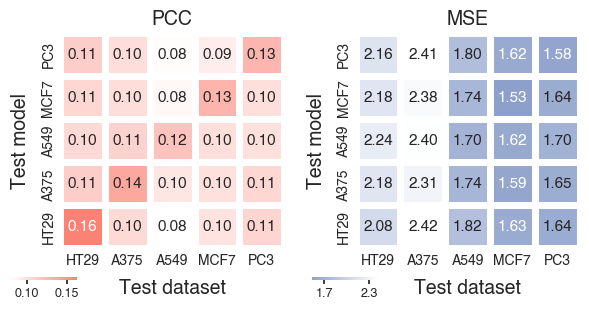

In [14]:
# Generate heatmaps
fig, axs = plt.subplots(1, 2, figsize=(6.7, 4)) 
plt.subplots_adjust(wspace=0.32)

# PCC Heatmap
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["w", "#FB8275"]) 

plt.subplot(1, 2, 1)
heatmap = sns.heatmap(
    pcc_df.loc[clss, clss[::-1]].T, 
    annot=True, 
    annot_kws={"size": 11},
    fmt=".2f", 
    cmap=custom_cmap, 
    linewidths=5, 
    linecolor='white', 
    cbar_kws={"shrink": 0.5, "location": "bottom"}
    )
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(length=3, pad=2, labelsize=9)
cbar.ax.set_position([0.05, 0.22, 0.1, 0.05])
plt.title('PCC', fontsize=14)
plt.xlabel('Test dataset', fontsize=14, labelpad=8)
plt.ylabel('Test model', fontsize=14, labelpad=8)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tick_params(axis='both', which='both', length=0)

# MSE Heatmap
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#8DA0CB", "w"])
plt.subplot(1, 2, 2)
heatmap = sns.heatmap(
    mse_df.loc[clss, clss[::-1]].T, 
    annot=True, 
    annot_kws={"size": 11},
    fmt=".2f", 
    cmap=custom_cmap, 
    linewidths=5, 
    linecolor='white', 
    cbar_kws={"shrink": 0.5, "location": "bottom"}
    )
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(length=3, pad=2, labelsize=9)
cbar.ax.set_xticks([1.7, 2.3])
cbar.ax.set_xticklabels(['1.7', '2.3'])
cbar.ax.set_position([0.5, 0.22, 0.1, 0.05])
plt.title('MSE', fontsize=14)
plt.xlabel('Test dataset', fontsize=14, labelpad=8)
plt.ylabel('Test model', fontsize=14, labelpad=8)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tick_params(axis='both', which='both', length=0)

plt.show()